In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

DATA_PATH = "../dataset/house_price_dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isna().sum())

numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

for col in numeric_cols:
    if col not in ["House_ID", "Price"]:
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum())


Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277.0
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512.0
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806.0
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776.0
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975.0



Missing values:
 House_ID                         0
Area_sqft                      603
Bedrooms                       450
Bathrooms                      300
Floors                           0
Year_Built                       0
Location                       751
Furnishing_Status              901
Parking_Available              603
Garage_Count                   300
Lot_Size_sqft                  450
Condition                      450
Distance_to_City_Center_km     300
Crime_Rate_Index                 0
School_Rating                 1051
Has_Pool                         0
Renovated                        0
Price                            0
dtype: int64
House_ID                      0
Area_sqft                     0
Bedrooms                      0
Bathrooms                     0
Floors                        0
Year_Built                    0
Location                      0
Furnishing_Status             0
Parking_Available             0
Garage_Count                  0
Lot_Size_sqft      

In [8]:
# Calculate median house price
price_median = df["Price"].median()

# Create binary target variable
# 0 = Below median price
# 1 = Equal to or above median price

df["Price_Class"] = (df["Price"] >= price_median).astype(int)

# Separate independent and dependent variables
X = df.drop(columns=["Price", "Price_Class", "House_ID"])
y = df["Price_Class"]

print("Median Price:", price_median)

print("\nClass Distribution:")
print(y.value_counts())

Median Price: 359454.0

Class Distribution:
Price_Class
1    7513
0    7512
Name: count, dtype: int64


In [9]:


# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12020, 16)
Testing data: (3005, 16)


In [10]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Train model
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Below Median", "At/Above Median"]
))

Accuracy: 0.9108153078202995

Classification Report:
                 precision    recall  f1-score   support

   Below Median       0.91      0.91      0.91      1502
At/Above Median       0.91      0.91      0.91      1503

       accuracy                           0.91      3005
      macro avg       0.91      0.91      0.91      3005
   weighted avg       0.91      0.91      0.91      3005



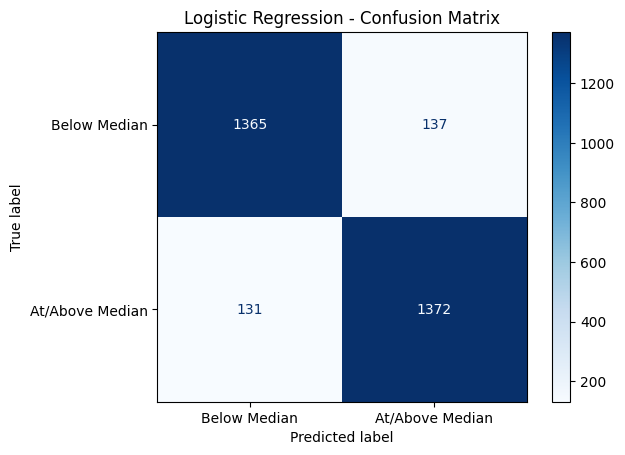

In [12]:
# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Below Median", "At/Above Median"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [14]:
# Select one sample from testing data
sample = X_test.iloc[[0]]

# Predict class
prediction = model.predict(sample)[0]

# Display result
if prediction == 1:
    print("Predicted Class: At or Above Median Price")
else:
    print("Predicted Class: Below Median Price")

# Display prediction probabilities
print("\nPrediction Probabilities:")
print("Below Median, At/Above Median")
print(model.predict_proba(sample)[0])

Predicted Class: Below Median Price

Prediction Probabilities:
Below Median, At/Above Median
[0.94020889 0.05979111]
